In [11]:

import pandas as pd
import numpy as np
from google.colab import files
from sklearn.model_selection import StratifiedGroupKFold

# Upload Parkinson's Excel dataset
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_excel(file_name, header=1)

# Separate ID, features and target
groups = df["id"]
X = df.drop(columns=["id", "class"])
y = df["class"]

print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts())
print("\nNumber of participants:", groups.nunique())
print("\nMissing values:", X.isnull().sum().sum())

# Participant-level train-test split
outer_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

train_idx, test_idx = next(outer_cv.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training participants:", groups_train.nunique())
print("Testing participants:", groups_test.nunique())

assert set(groups_train).isdisjoint(set(groups_test))
print("Participant leakage check: Passed")


Saving pd_speech_features.csv.xlsx to pd_speech_features.csv.xlsx
Dataset shape: (756, 755)
Feature shape: (756, 753)

Class distribution:
class
1    564
0    192
Name: count, dtype: int64

Number of participants: 252

Missing values: 0

Training samples: 603
Testing samples: 153
Training participants: 201
Testing participants: 51
Participant leakage check: Passed


In [12]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from sklearn.base import clone
import pandas as pd
import numpy as np

# Base classifiers
base_models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(), StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(),
        RandomForestClassifier(n_estimators=200, random_state=42)
    ),
    "SVM": make_pipeline(
        SimpleImputer(), StandardScaler(),
        SVC(probability=True, random_state=42)
    ),
    "KNN": make_pipeline(
        SimpleImputer(), StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )
}

# Generate out-of-fold predictions for training data
inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

oof_predictions = np.zeros((len(X_train), len(base_models)))

for fold_train, fold_valid in inner_cv.split(
    X_train, y_train, groups_train
):
    for j, (name, model) in enumerate(base_models.items()):
        fitted_model = clone(model)
        fitted_model.fit(
            X_train.iloc[fold_train], y_train.iloc[fold_train]
        )
        oof_predictions[fold_valid, j] = (
            fitted_model.predict_proba(
                X_train.iloc[fold_valid]
            )[:, 1]
        )

# Train base models on the complete training set
test_predictions = np.zeros((len(X_test), len(base_models)))

for j, (name, model) in enumerate(base_models.items()):
    fitted_model = clone(model)
    fitted_model.fit(X_train, y_train)
    test_predictions[:, j] = fitted_model.predict_proba(X_test)[:, 1]

# Alternative meta-classifiers
meta_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    )
}

# Evaluate stacking models
results = []

for name, meta_model in meta_models.items():
    meta_model.fit(oof_predictions, y_train)

    predictions = meta_model.predict(test_predictions)
    probabilities = meta_model.predict_proba(test_predictions)[:, 1]

    results.append({
        "Meta Classifier": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Meta Classifier,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8235,0.8480,0.9298,0.8870,0.8646
1,Random Forest,0.7647,0.8250,0.8684,0.8462,0.7885
2,SVM,0.8170,0.8468,0.9211,0.8824,0.7569


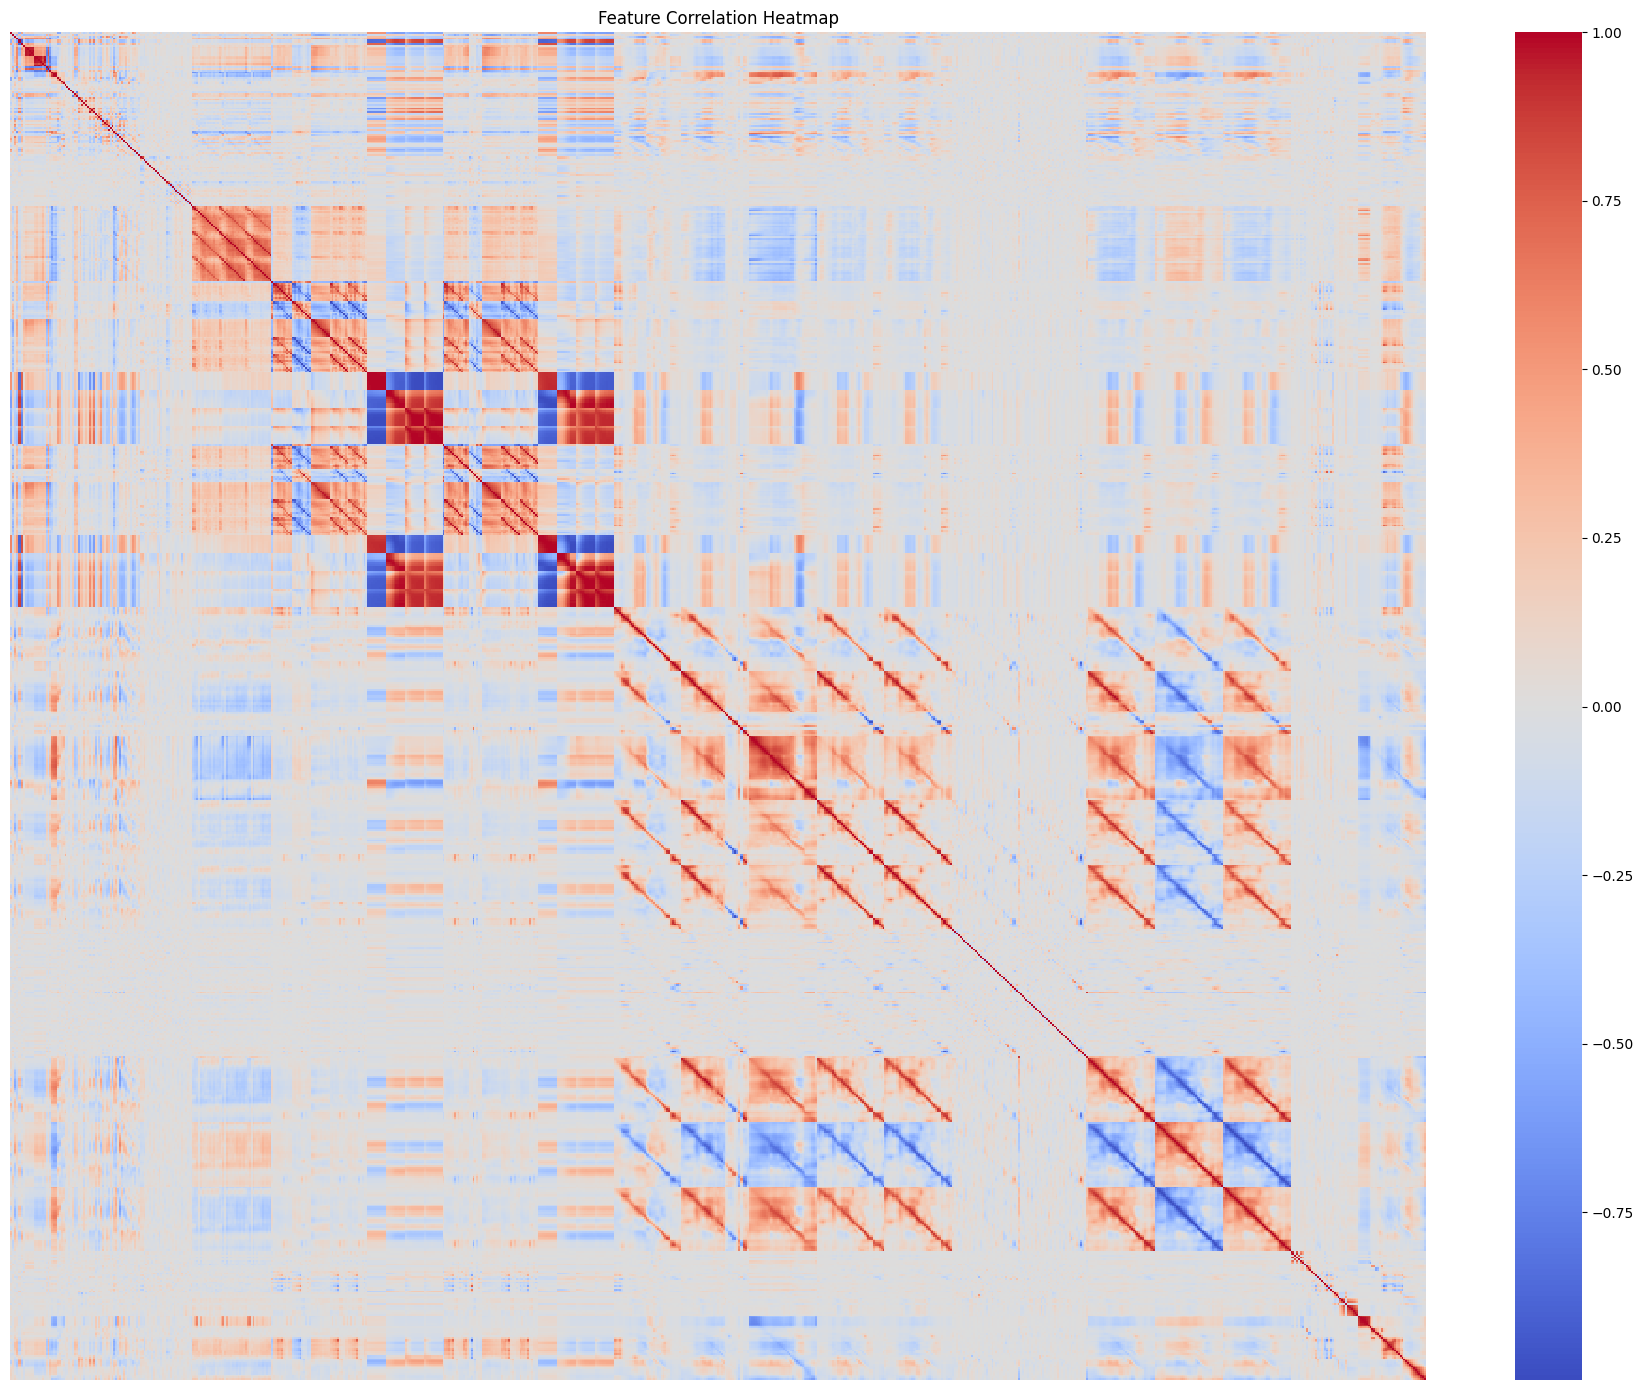

Total highly correlated feature pairs: 2139

Top 20 highly correlated pairs:


,Feature 1,Feature 2,Correlation
11177,apq3Shimmer,ddaShimmer,1.000000
179843,app_LT_entropy_log_8_coef,app_LT_entropy_log_9_coef,1.000000
175248,app_LT_entropy_shannon_8_coef,app_LT_entropy_shannon_9_coef,1.000000
180297,app_LT_entropy_log_9_coef,app_LT_entropy_log_10_coef,1.000000
179844,app_LT_entropy_log_8_coef,app_LT_entropy_log_10_coef,1.000000
134343,app_entropy_log_8_coef,app_entropy_log_9_coef,1.000000
175712,app_LT_entropy_shannon_9_coef,app_LT_entropy_shannon_10_coef,1.000000
128838,app_entropy_shannon_8_coef,app_entropy_shannon_9_coef,1.000000
175249,app_LT_entropy_shannon_8_coef,app_LT_entropy_shannon_10_coef,0.999999
129393,app_entropy_shannon_9_coef,app_entropy_shannon_10_coef,0.999998


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Calculate feature correlations
correlation_matrix = X_train.corr()

# Plot correlation heatmap
plt.figure(figsize=(18, 14))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Identify highly correlated feature pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr = high_corr[
    high_corr["Correlation"].abs() >= 0.90
].sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

print("Total highly correlated feature pairs:", len(high_corr))
print("\nTop 20 highly correlated pairs:")
display(high_corr.head(20))

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.base import clone
import pandas as pd

# Preprocessing and PCA
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

pca = PCA(n_components=0.99, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train.shape[1])
print("Number of PCA components:", X_train_pca.shape[1])
print("Explained variance retained:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# Classifiers
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []

for name, model in models.items():
    for data_name, train_data, test_data in [
        ("Original Features", X_train_scaled, X_test_scaled),
        ("PCA Features", X_train_pca, X_test_pca)
    ]:
        clf = clone(model)
        clf.fit(train_data, y_train)

        predictions = clf.predict(test_data)
        probabilities = clf.predict_proba(test_data)[:, 1]

        results.append({
            "Classifier": name,
            "Feature Set": data_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1 Score": f1_score(y_test, predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, probabilities)
        })

results_a3 = pd.DataFrame(results)
display(results_a3.round(4))

Original number of features: 753
Number of PCA components: 255
Explained variance retained: 99.01 %


,Classifier,Feature Set,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,Original Features,0.7778,0.8636,0.8333,0.8482,0.7906
1,Logistic Regression,PCA Features,0.7647,0.8611,0.8158,0.8378,0.7861
2,Random Forest,Original Features,0.8366,0.8450,0.9561,0.8971,0.8526
3,Random Forest,PCA Features,0.7647,0.7868,0.9386,0.8560,0.7729
4,SVM,Original Features,0.8170,0.8209,0.9649,0.8871,0.8513
5,SVM,PCA Features,0.8301,0.8333,0.9649,0.8943,0.8531
6,KNN,Original Features,0.8366,0.8504,0.9474,0.8963,0.7661
7,KNN,PCA Features,0.8366,0.8504,0.9474,0.8963,0.7727
